# Explorer 05 - Snapshot comparison

**Purpose.** Diff January 2020 against October 2026: which labels changed parent, and how late releases get catalogued.

**Feeds main report section:** 5.4 Snapshot comparison, and 7. Limitations

**Modules used:** `vinyl.snapshots`, `vinyl.labels`, `vinyl.viz`

**Tables read:** `labels` and `releases` from both snapshots

This is a working notebook. It can be messy; anything that goes into the report is re-run from `main.ipynb` through the same functions in `vinyl/`.

In [1]:
# Make the `vinyl` package importable from the explorers/ folder.
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "explorers":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

%load_ext autoreload
%autoreload 2

from pyspark.sql import functions as F
from vinyl import config, ingest

spark = ingest.get_spark(app_name="vinyl-05-snapshots", shuffle_partitions=8)
from vinyl import snapshots, viz

In [2]:
# Cache the labels tables: the root walk and the parent chains read them many times.
old, new = config.BASE_SNAPSHOT, config.MAIN_SNAPSHOT   # "2020", "2026"
label_cols = ["label_id", "label_name", "parent_id", "parent_name"]
labels_old = ingest.read_table(spark, old, "labels").select(*label_cols).cache()
labels_new = ingest.read_table(spark, new, "labels").select(*label_cols).cache()
releases_old, releases_new = ingest.read_table(spark, old, "releases"), ingest.read_table(spark, new, "releases")

## 1. Labels whose parent changed

In [3]:
changes = snapshots.label_parent_changes(labels_old, labels_new).cache()
changes.groupBy("change").count().orderBy(F.desc("count")).show()

+--------------+-------+
|        change|  count|
+--------------+-------+
|     unchanged|1280637|
|     new_label|1041069|
| gained_parent|  98619|
| removed_label|  76517|
|changed_parent|   4232|
|   lost_parent|   1518|
+--------------+-------+



In [4]:
# Biggest ownership changes: rank changed labels by how many in-scope releases they have.
release_labels = ingest.read_table(spark, new, "release_labels")
volume = release_labels.groupBy("label_id").agg(F.countDistinct("release_id").alias("n_releases"))
(changes.where(F.col("change").isin("changed_parent", "gained_parent", "lost_parent"))
    .join(volume, "label_id").orderBy(F.desc("n_releases")).show(30, truncate=False))

+--------+---------------------+-------------+-------------------------------------------------------+-------------+------------------------------------------------+--------------+----------+
|label_id|label_name           |parent_id_old|parent_name_old                                        |parent_id_new|parent_name_new                                 |change        |n_releases|
+--------+---------------------+-------------+-------------------------------------------------------+-------------+------------------------------------------------+--------------+----------+
|1818    |Not On Label         |NULL         |NULL                                                   |205754       |Stolen Riff Records                             |gained_parent |187763    |
|38404   |Universal Music Group|NULL         |NULL                                                   |212          |NULL                                            |gained_parent |11123     |
|1003    |BMG                  |353658  

### Do the three majors' root labels exist in both snapshots?

`config.MAJOR_ROOT_IDS` was checked against the 2026 table only. A root that is missing in 2020, or has a different parent there, is printed below.

In [5]:
roots = snapshots.major_root_check(labels_old, labels_new)
print(roots.to_string(index=False))
for r in roots[~roots.ok].itertuples():
    print(f"CHECK {r.major} (root {r.root_id}): in 2020={r.in_old}, in 2026={r.in_new}, "
          f"parent in 2020={r.parent_id_old}, parent in 2026={r.parent_id_new}")
if roots.ok.all():
    print("All three roots exist in both snapshots with the same parent.")

    major  root_id  in_old  in_new        label_name_old        label_name_new  parent_id_old  parent_id_new    ok
Universal    38404    True    True Universal Music Group Universal Music Group           <NA>            212 False
     Sony   353657    True    True      Sony Corporation      Sony Corporation           <NA>           <NA>  True
   Warner     2345    True    True    Warner Music Group    Warner Music Group           <NA>            212 False
CHECK Universal (root 38404): in 2020=True, in 2026=True, parent in 2020=<NA>, parent in 2026=212
CHECK Warner (root 2345): in 2020=True, in 2026=True, parent in 2020=<NA>, parent in 2026=212


### Moves into and out of a major tree

Roots are resolved in each snapshot separately (placeholder parent 212 is not followed). `n_releases` counts distinct releases on the label in the 2026 `release_labels` table.

In [6]:
moves = snapshots.major_moves(labels_old, labels_new, release_labels).cache()
print(f"{moves.count():,} labels changed major between the snapshots")
(moves.groupBy("major_old", "major_new")
    .agg(F.count("*").alias("n_labels"), F.sum("n_releases").alias("n_releases"))
    .orderBy(F.desc("n_labels")).show(truncate=False))

5,051 labels changed major between the snapshots


+-----------+-----------+--------+----------+
|major_old  |major_new  |n_labels|n_releases|
+-----------+-----------+--------+----------+
|Independent|Universal  |2108    |11399     |
|Independent|Sony       |911     |7781      |
|Independent|Warner     |899     |2981      |
|Universal  |Independent|571     |3014      |
|Sony       |Independent|256     |577       |
|Warner     |Independent|210     |3203      |
|Warner     |Universal  |78      |124       |
|Universal  |Warner     |14      |22        |
|Universal  |Sony       |2       |577       |
|Sony       |Universal  |2       |0         |
+-----------+-----------+--------+----------+



In [7]:
(moves.select("label_id", "label_name", "major_old", "major_new", "move", "n_releases")
    .show(30, truncate=False))

+--------+-------------------------+-----------+-----------+--------------+----------+
|label_id|label_name               |major_old  |major_new  |move          |n_releases|
+--------+-------------------------+-----------+-----------+--------------+----------+
|750     |Virgin                   |Independent|Universal  |into_major    |2189      |
|133449  |[PIAS]                   |Independent|Universal  |into_major    |1912      |
|720     |disco:wax                |Independent|Sony       |into_major    |1461      |
|674471  |Caroline International   |Universal  |Independent|out_of_major  |786       |
|969792  |HEXAGON (3)              |Warner     |Independent|out_of_major  |714       |
|19369   |Harmonia Mundi           |Independent|Universal  |into_major    |711       |
|26215   |Play It Again Sam        |Independent|Universal  |into_major    |680       |
|555808  |Quality Control Music (2)|Universal  |Independent|out_of_major  |595       |
|29600   |Erato                    |Warner 

### Hand-check the top moves

**Reading rule.** A real acquisition is a new parent that is a known corporate entity, often with an `(n)` suffix in its name, for example a Warner company. A data correction is a parent that flips between a placeholder, a duplicate or a similar-name profile, or a fix to the chain above the label.

Each table below is the parent chain of one label in the 2020 (`old`) and the 2026 (`new`) snapshot.

In [8]:
import pandas as pd
pd.set_option("display.width", 200)
for row in moves.limit(5).collect():
    print(f"=== {row.label_id} {row.label_name}: {row.major_old} -> {row.major_new} ({row.n_releases:,} releases)")
    print(snapshots.explain_move(row.label_id, labels_old, labels_new).drop(columns="label_id").to_string(index=False))

=== 750 Virgin: Independent -> Universal (2,189 releases)


snapshot  hop                         label_name  parent_id                        parent_name                             note
     old    0                             Virgin   326037.0            Virgin Enterprises Ltd.                                 
     old    1            Virgin Enterprises Ltd.        NaN                               None                             root
     new    0                             Virgin    26760.0                Virgin Records Ltd.                                 
     new    1                Virgin Records Ltd.  1330982.0                     EMI Group Ltd.                                 
     new    2                     EMI Group Ltd.   220303.0 Universal International Music B.V.                                 
     new    3 Universal International Music B.V.    38404.0              Universal Music Group                                 
     new    4              Universal Music Group      212.0                               None placehold

snapshot  hop                 label_name  parent_id                parent_name                             note
     old    0                     [pias]   142816.0 [PIAS] Entertainment Group                                 
     old    1 [PIAS] Entertainment Group        NaN                       None                             root
     new    0                     [PIAS]   142816.0 [PIAS] Entertainment Group                                 
     new    1 [PIAS] Entertainment Group  3156497.0         Virgin Music Group                                 
     new    2         Virgin Music Group    38404.0      Universal Music Group                                 
     new    3      Universal Music Group      212.0                       None placeholder parent, not followed
=== 720 disco:wax: Independent -> Sony (1,461 releases)


snapshot  hop                           label_name  parent_id                          parent_name note
     old    0                            disco:wax        NaN                                 None root
     new    0                            disco:wax   268343.0 Sony Music Entertainment Denmark A/S     
     new    1 Sony Music Entertainment Denmark A/S    29073.0             Sony Music Entertainment     
     new    2             Sony Music Entertainment    19795.0        Sony Music Entertainment Inc.     
     new    3        Sony Music Entertainment Inc.   353657.0                     Sony Corporation     
     new    4                     Sony Corporation        NaN                                 None root
=== 674471 Caroline International: Universal -> Independent (786 releases)


snapshot  hop             label_name  parent_id            parent_name note
     old    0 Caroline International  1334511.0           Caroline (5)     
     old    1           Caroline (5)   145028.0  Caroline Distribution     
     old    2  Caroline Distribution   126439.0    Capitol Music Group     
     old    3    Capitol Music Group    38404.0  Universal Music Group     
     old    4  Universal Music Group        NaN                   None root
     new    0 Caroline International      952.0       Caroline Records     
     new    1       Caroline Records    52512.0 Caroline Records, Inc.     
     new    2 Caroline Records, Inc.        NaN                   None root
=== 969792 HEXAGON (3): Warner -> Independent (714 releases)


snapshot  hop         label_name  parent_id        parent_name                             note
     old    0        HEXAGON (3)     2178.0   Spinnin' Records                                 
     old    1   Spinnin' Records     2345.0 Warner Music Group                                 
     old    2 Warner Music Group        NaN               None                             root
     new    0        HEXAGON (3)  1631279.0 Hexagon Music B.V.                                 
     new    1 Hexagon Music B.V.      212.0               None placeholder parent, not followed


## 2. Cataloguing lag

In [9]:
lag = snapshots.cataloguing_lag(releases_old, releases_new)
lag_pd = lag.toPandas()
lag_pd

,year,n_new,n_already,n_added_later,completeness
0,2016,385281,293460,91821,0.761678
1,2017,390355,290455,99900,0.744079
2,2018,396710,274727,121983,0.692513
3,2019,394016,215579,178437,0.547133
4,2020,415671,581,415090,0.001398
5,2021,391297,78,391219,0.000199
6,2022,360863,33,360830,0.000091
7,2023,347065,20,347045,0.000058
8,2024,312179,9,312170,0.000029
9,2025,280882,13,280869,0.000046


<Axes: title={'left': "Share of each year's releases already catalogued by January 2020, release years 2016-2019"}, xlabel='year', ylabel='share already catalogued'>

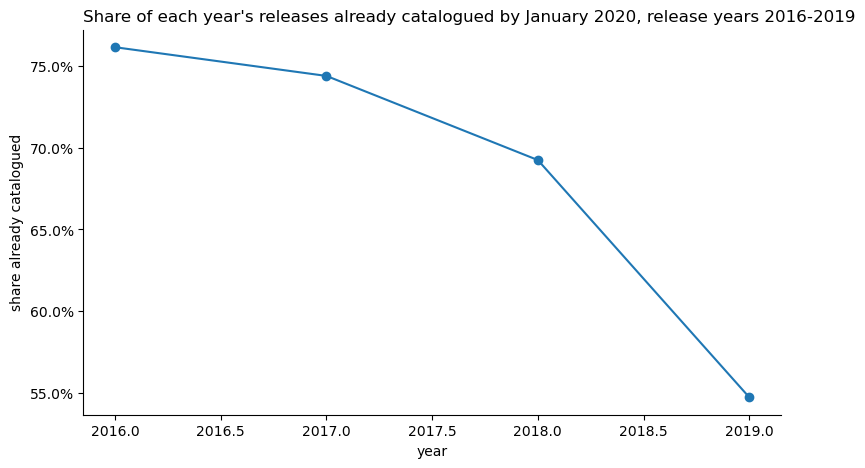

In [10]:
viz.plot_lines(lag_pd[lag_pd.year <= 2019], "year", "completeness",
               title="Share of each year's releases already catalogued by January 2020, release years 2016-2019",
               ylabel="share already catalogued", percent=True)

Completeness by age, where `age = 2020 - year`. Only `year <= 2019` is used: 2020 in the January 2020 snapshot is a stub of a few days.

In [11]:
by_age = lag_pd[lag_pd.year <= 2019].assign(age=lambda d: int(old) - d.year)
print(by_age[["age", "year", "n_new", "n_already", "n_added_later", "completeness"]]
      .sort_values("age").to_string(index=False))

 age  year  n_new  n_already  n_added_later  completeness
   1  2019 394016     215579         178437      0.547133
   2  2018 396710     274727         121983      0.692513
   3  2017 390355     290455          99900      0.744079
   4  2016 385281     293460          91821      0.761678


## 3. Estimated undercount of recent years

In [12]:
yearly = releases_new.groupBy("year").agg(F.count("*").alias("n_releases"))
est_pd = snapshots.estimate_undercount(lag, yearly).toPandas()
est_pd[["year", "n_releases", "age", "completeness", "partial_year", "n_estimated"]]

,year,n_releases,age,completeness,partial_year,n_estimated
0,2016,385281,11,NaN,False,385281.000000
1,2017,390355,10,NaN,False,390355.000000
2,2018,396710,9,NaN,False,396710.000000
3,2019,394016,8,NaN,False,394016.000000
4,2020,415671,7,NaN,False,415671.000000
5,2021,391297,6,NaN,False,391297.000000
6,2022,360863,5,NaN,False,360863.000000
7,2023,347065,4,0.761678,False,455658.523359
8,2024,312179,3,0.744079,False,419550.820420
9,2025,280882,2,0.692513,False,405597.914366


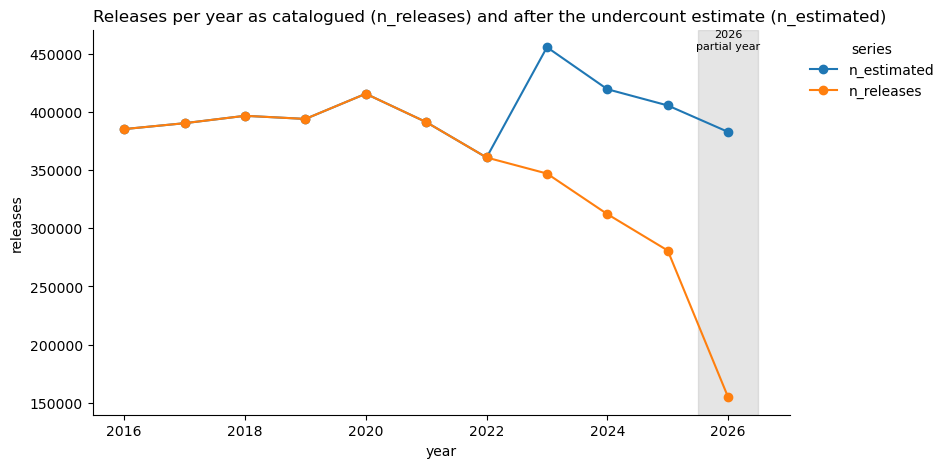

In [13]:
long = est_pd.melt(id_vars="year", value_vars=["n_releases", "n_estimated"], var_name="series", value_name="n")
ax = viz.plot_lines(long, "year", "n", series="series", ylabel="releases",
                    title="Releases per year as catalogued (n_releases) and after the undercount estimate (n_estimated)")
for y in est_pd.loc[est_pd.partial_year, "year"]:
    ax.axvspan(y - 0.5, y + 0.5, color="grey", alpha=0.2)
    ax.text(y, ax.get_ylim()[1], f"{y}\npartial year", ha="center", va="top", fontsize=8)

The same estimate without the seasonal correction (`partial_year_share={}`), next to the corrected one, to show the size of the correction for the partial year.

In [14]:
est_flat = snapshots.estimate_undercount(lag, yearly, partial_year_share={}).toPandas()
compare = est_pd[["year", "n_releases", "partial_year", "n_estimated"]].merge(
    est_flat[["year", "n_estimated"]].rename(columns={"n_estimated": "n_estimated_no_seasonal"}), on="year")
compare["seasonal_factor"] = compare.n_estimated / compare.n_estimated_no_seasonal
print(compare.to_string(index=False))

 year  n_releases  partial_year   n_estimated  n_estimated_no_seasonal  seasonal_factor
 2016      385281         False 385281.000000            385281.000000          1.00000
 2017      390355         False 390355.000000            390355.000000          1.00000
 2018      396710         False 396710.000000            396710.000000          1.00000
 2019      394016         False 394016.000000            394016.000000          1.00000
 2020      415671         False 415671.000000            415671.000000          1.00000
 2021      391297         False 391297.000000            391297.000000          1.00000
 2022      360863         False 360863.000000            360863.000000          1.00000
 2023      347065         False 455658.523359            455658.523359          1.00000
 2024      312179         False 419550.820420            419550.820420          1.00000
 2025      280882         False 405597.914366            405597.914366          1.00000
 2026      154790          True 

## 4. Does the lag differ by format or genre?

Only the 2026 tables carry formats and genres, so each release is grouped by its 2026 formats or genres. A release with two formats counts once in each. `year <= 2019` only, as above.

format_name     CD  Cassette   File  Vinyl
age year                                  
1   2019     0.498     0.647  0.454  0.775
2   2018     0.629     0.813  0.629  0.869
3   2017     0.691     0.858  0.691  0.898
4   2016     0.690     0.882  0.728  0.910
format_name      CD  Cassette    File  Vinyl
age year                                    
1   2019      80554     24827  180665  86550
2   2018      90865     25350  174238  83660
3   2017     100989     24123  161321  78156
4   2016     107077     23270  152750  73730


<Axes: title={'left': 'Share already catalogued by January 2020, by format, release years 2016-2019'}, xlabel='year', ylabel='share already catalogued'>

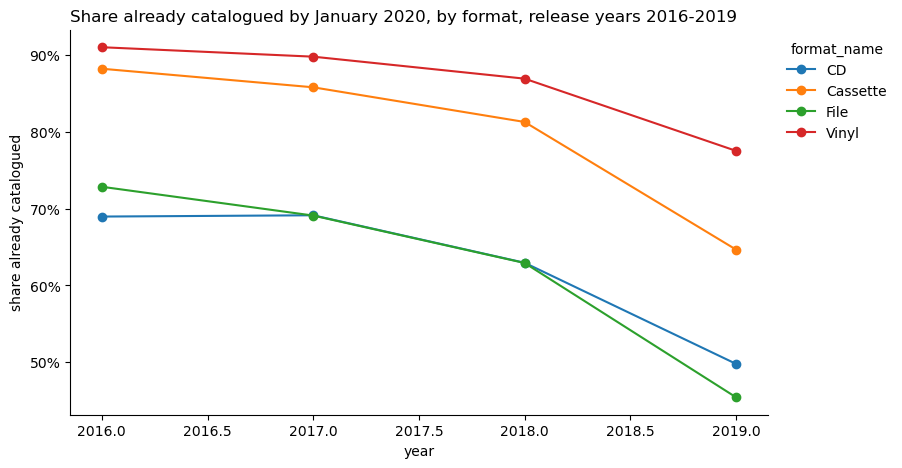

In [15]:
early = releases_new.where(F.col("year") <= 2019).select("release_id", "year").cache()
formats_new = ingest.read_table(spark, new, "release_formats")
lag_fmt = snapshots.cataloguing_lag_by(
    releases_old, early, formats_new.where(F.col("format_name").isin("Vinyl", "CD", "Cassette", "File")),
    "format_name").toPandas().assign(age=lambda d: int(old) - d.year)
print(lag_fmt.pivot(index=["age", "year"], columns="format_name", values="completeness").round(3).to_string())
print(lag_fmt.pivot(index=["age", "year"], columns="format_name", values="n_new").to_string())
viz.plot_lines(lag_fmt, "year", "completeness", series="format_name", percent=True,
               title="Share already catalogued by January 2020, by format, release years 2016-2019",
               ylabel="share already catalogued")

['Electronic', 'Rock', 'Pop', 'Hip Hop', 'Folk, World, & Country', 'Jazz', 'Funk / Soul', 'Classical']


genre     Classical  Electronic  Folk, World, & Country  Funk / Soul  Hip Hop   Jazz    Pop   Rock
age year                                                                                          
1   2019      0.357       0.578                   0.441        0.585    0.464  0.522  0.471  0.589
2   2018      0.535       0.737                   0.571        0.702    0.632  0.647  0.613  0.717
3   2017      0.677       0.784                   0.629        0.750    0.705  0.712  0.679  0.761
4   2016      0.568       0.806                   0.647        0.769    0.762  0.715  0.697  0.783
genre     Classical  Electronic  Folk, World, & Country  Funk / Soul  Hip Hop   Jazz    Pop    Rock
age year                                                                                           
1   2019      10499      177753                   25963        13259    29301  18175  50447  137136
2   2018      11517      176605                   26591        13650    28789  18954  50761  141048
3   20

<Axes: title={'left': 'Share already catalogued by January 2020, by genre (top 8), release years 2016-2019'}, xlabel='year', ylabel='share already catalogued'>

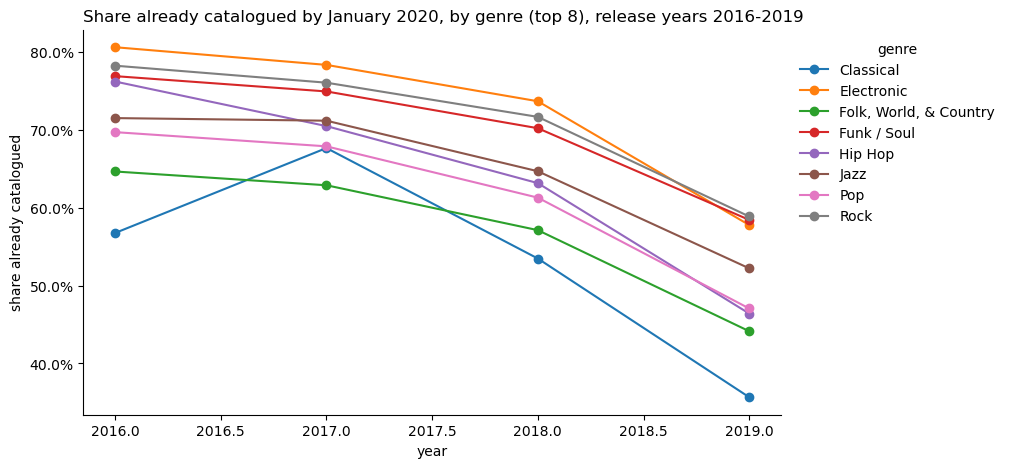

In [16]:
genres_new = ingest.read_table(spark, new, "release_genres")
top_genres = [r.genre for r in (genres_new.where(F.col("year") <= 2019).groupBy("genre")
              .agg(F.countDistinct("release_id").alias("n")).orderBy(F.desc("n")).limit(8).collect())]
print(top_genres)
lag_gen = snapshots.cataloguing_lag_by(
    releases_old, early, genres_new.where(F.col("genre").isin(top_genres)), "genre"
).toPandas().assign(age=lambda d: int(old) - d.year)
print(lag_gen.pivot(index=["age", "year"], columns="genre", values="completeness").round(3).to_string())
print(lag_gen.pivot(index=["age", "year"], columns="genre", values="n_new").to_string())
viz.plot_lines(lag_gen, "year", "completeness", series="genre", percent=True,
               title="Share already catalogued by January 2020, by genre (top 8), release years 2016-2019",
               ylabel="share already catalogued")

**Reading rule.** If completeness for the same age differs between groups, then in the October 2026 snapshot the most recent years are undercounted by different amounts per group, and recent-year shares are biased toward the faster-catalogued groups. If the groups have about the same completeness at each age, shares are not biased by the lag, even though counts are.

## Decisions to carry into `main.ipynb`

Filled in from the full-data runs in `executed/`. Each line should end up as a sentence in the report's methodology or limitations.

- [x] Ownership changes named in the report: Virgin (Independent to Universal, 2,189 releases, through a filled-in chain via EMI Group Ltd.), [PIAS] (to Universal via Virgin Music Group, 1,912) and disco:wax (to Sony, 1,461) into a major; Caroline International (786) and HEXAGON (714) out of one; Alamo Records (Universal to Sony, 552) between two. 5,051 labels changed major in all.
- [x] Completeness by age: 54.7% at 1 year, 69.3% at 2, 74.4% at 3 and 76.2% at 4. 2023-2026 are flagged as undercounted: 2025 has 280,882 catalogued releases against an estimated 405,598, and 2026 has 154,790 against 382,830 for the full year with the seasonal factor of 0.739.
- [x] Trend charts show 2016-2026 with 2026 shaded as partial; comparisons and style movers end in 2025 (`config.LAST_FULL_YEAR`), and the lag is stated as a caveat because it differs by format (vinyl 77.5% against File 45.4% at 1 year).